# Example: Analysis of a Straddle Position in AMD
In this example, we will analyze a straddle position in Advanced Micro Devices, Inc. (AMD) using historical options data. A long (short) straddle involves buying (selling) both a call and a put option at the same strike price and expiration date, allowing the trader to profit from significant (limited) price movements in either direction. We sell a straddle on AMD before its earnings release, so our position profits if the share price stays near the strike price.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Construct profit diagrams for straddle positions:__ Build profit and loss profiles for long and short straddles by combining put and call contracts with the same strike price and expiration date, and compute breakeven points where the position transitions from profit to loss.
> * __Calculate the probability of profit and the probability of exercise for a straddle:__ Use cumulative distribution functions of projected share price distributions to determine the likelihood that a straddle will be profitable at expiration, accounting for the two breakeven boundaries, and each leg's probability of exercise, under our belief $\mathbb{P}$ and the risk-neutral probabilities $\mathbb{Q}$.
> * __Evaluate the straddle after the earnings release:__ Buy both legs back at their premiums after the release and compute the profit or loss, which includes the extrinsic value still left in the legs.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
To start, load the options data using [the `MyOptionsChainDataSet(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyOptionsChainDataSet) and store the metadata in the `metadata::Dict{String,Any}` variable and the options chain data in the `optionschain::DataFrame` variable.

In [2]:
metadata, optionschain = let
    
    # initialize -
    options_dataset = MyOptionsChainDataSet(ticker="amd-2026");
    metadata = options_dataset.metadata;
    optionschain = options_dataset.data;

    (metadata, optionschain) # return
end;

What's in the `metadata::Dict{String,Any}` dictionary?

In [3]:
metadata |> keys

KeySet for a Dict{String, Any} with 10 entries. Keys:
  "DTE"
  "purchase_date"
  "historical_volatility"
  "underlying_share_price_ask"
  "source"
  "underlying_share_price_bid"
  "is_weekly"
  "atm_IV"
  "expiration_date"
  "underlying_share_price_mid"

In [4]:
metadata["purchase_date"]

"2026-10-26"

In [5]:
metadata["underlying_share_price_mid"] |> x-> parse(Float64, x)

531.26

In [6]:
metadata["atm_IV"]

"0.5617"

What about the `optionschain::DataFrame` variable?

In [7]:
optionschain

Row,Strike,Moneyness,Bid,Mid,Ask,Last,Volume,Open Int,IV,Delta,Type
,Float64,Float64,Float64,Float64,Float64,Float64,Int64,String7,Float64,Float64,String7
1,5.0,0.9906,524.2,526.53,528.85,517.3,0,"1,074",5.2163,0.9996,Call
2,10.0,0.9812,518.9,521.4,523.9,479.51,0,4,3.7202,0.9998,Call
3,15.0,0.9718,514.3,516.63,518.95,0.0,0,0,3.8539,0.9992,Call
4,20.0,0.9624,509.3,511.63,513.95,466.97,0,956,3.4532,0.9992,Call
5,25.0,0.953,504.1,506.55,509.0,427.94,0,212,2.9877,0.9994,Call
6,30.0,0.9436,499.6,501.83,504.05,457.14,0,208,3.167,0.9986,Call
7,35.0,0.9342,494.65,496.85,499.05,479.33,0,9,2.9794,0.9985,Call
8,40.0,0.9247,488.4,491.17,493.95,483.4,1,13,1.9981,0.9999,Call
9,45.0,0.9153,484.25,486.7,489.15,425.63,0,101,2.4434,0.9991,Call


### Constants
Let's set the constants. The share price $S_{0}$ is AMD's close on the quote date. The step size `Δt::Float64` is one day in units of years (a `365-day` year), and `T::Float64` is the time to expiration. The risk-free rate $g_{y}$ is the 13-week Treasury bill yield on the quote date, converted to continuous compounding, and `𝒟::Float64` is the accumulation factor $\mathcal{D}_{T,0}(g_{y})=e^{g_{y}T}$ from today to expiration. Finally, `K::Float64` is the strike price of both legs, and the direction parameter `θ::Int64` is $-1$ because we sell both legs.

In [8]:
Sₒ = metadata["underlying_share_price_mid"] |> x-> parse(Float64, x); # close on the quote date, 2026-10-26 (USD/share)

Other constants:

In [9]:
Δt = (1/365); # one calendar day, expressed in years
DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (days)
T = DTE*Δt; # time to expiration (years)
τ_bill = 91/365; # term of the 13-week Treasury bill (years)
y_bill = 0.0415; # 13-week bill coupon-equivalent yield on 2026-10-26, U.S. Treasury Daily Treasury Bill Rates; update it if you change the quote date
# https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_bill_rates&field_tdr_date_value_month=202610
gᵧ = log(1 + y_bill*τ_bill)/τ_bill; # continuously compounded risk-free rate (1/yr)
𝒟 = exp(gᵧ*T); # accumulation factor from today to expiration (dimensionless)
K = 530.0; # strike price of both legs (USD/share)
θ = -1; # 1 = long straddle, -1 = short straddle

In this example, we'll need to do a projection of the future share price distribution at the contract's expiration date. We'll use a Geometric Brownian Motion (GBM) model to project the future share price distribution at expiration.

Let's load the single asset geometric Brownian motion (SAGBM) parameters which we estimated a few lectures ago, which include the drift and diffusion coefficients for each ticker. We'll store this data in the `parameters_df::DataFrame` variable:

In [10]:
parameters_df = let

    # load -
    df = CSV.read(joinpath(_PATH_TO_DATA,"SAGBM-Parameters-Fall-2025.csv"), DataFrame);
    df; # return
end;

We are looking at `AMD`, so let's see what the parameters for this ticker are:

In [11]:
filter(:ticker=> x-> x=="AMD", parameters_df)

Row,ticker,drift,t,lower_bound_drift,upper_bound_drift,volatility
,String7,Float64,Float64,Float64,Float64,Float64
1,AMD,0.439658,1.96082,0.43459,0.444725,0.474283


### Contract models
Next, we construct contract models for the options in this example. We begin by building an instance of the [MyAmericanCallContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanCallContractModel) using the [custom build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}). The [build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}) takes two arguments: the type to build, and a [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) containing the strike price `K`, the `premium` paid for the option, the days to expiration `DTE` (units: years), the `sense` parameter for position direction, the number of contracts in the `copy` field and the implied volatility in the `IV` field.

We save the call option contract model in the `call_option_model::MyAmericanCallContractModel` variable:

In [12]:
call_option_model = let

    # initialize -
    options_dataset =  optionschain;
    premium = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Call"), options_dataset)[1,:Mid];
    IV = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Call"), options_dataset)[1,:IV]; # implied volatility (decimal)
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)


    # build the contract model -
    call_option_model = build(MyAmericanCallContractModel, (
        K = K, 
        premium = premium, # mark price
        DTE = DTE*Δt, # units: years
        sense = θ,
        copy = 1,
        IV = IV
    ));

    call_option_model; # return the model -
end

MyAmericanCallContractModel(530.0, -1, 0.1452054794520548, 0.5683, 47.83, nothing, 1)

The put contract, which is an instance of the [MyAmericanPutContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanPutContractModel), is constructed in a similar way to the call option. We save the put option contract model in the `put_option_model::MyAmericanPutContractModel` variable:

In [13]:
put_option_model = let

    # initialize -
    options_dataset =  optionschain;
    premium = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:Mid];
    IV = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:IV]; # implied volatility (decimal)
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)

    # build the contract model -
    put_option_model = build(MyAmericanPutContractModel, (
        K = K, 
        premium = premium, # mark price
        DTE = DTE*Δt, # units: years
        sense = θ,
        copy = 1,
        IV = IV
    ));

    put_option_model; # return the model -
end

MyAmericanPutContractModel(530.0, -1, 0.1452054794520548, 0.5595, 43.0, nothing, 1)

___

## Task 1: Compute Profit, Loss and Breakeven Points
In this task, we compute the profit and loss (P&L) profile of our short straddle at expiration, as well as its breakeven points.

A [straddle](https://www.investopedia.com/terms/s/straddle.asp) is a _neutral strategy_ constructed by simultaneously buying (or selling) a put and a call option on the same underlying asset `XYZ`, with the _same expiration_, and the _same strike price_. 

> __Long (short) straddle__
> 
> Let's build a long (short) straddle on AMD whose current share price is $S(0) = 531.26$ USD/share. For a long straddle, we purchase (are long) both the put and the call contracts in the straddle ($\theta = 1$). For a short straddle, we sell (are short) both the put and the call contracts in the straddle ($\theta = -1$). For a straddle, both legs have the same strike price $K$.
>
> Let's construct the profit diagram for a long (short) straddle with the parameters:
> * Leg 1: The strike price for the long (short) put leg is given by $K_{1}$ = 530 USD/share with DTE = 53 days
> * Leg 2: The strike price for the long (short) call leg is given by $K_{2}$ = 530 USD/share with DTE = 53 days
>
> In this example, we sell both legs ($\theta = -1$).

### Profit and Breakeven Analysis
Both legs have the same strike price $K$. Let $\mathcal{P}_{p}$ and $\mathcal{P}_{c}$ denote the premiums of the put and the call (USD/share), and let $\mathcal{D}_{T,0}(g_{y})$ be the accumulation factor from today to expiration. The premiums are paid today and the payoffs arrive at expiration, so the profit of a single straddle at expiration $\hat{P}_{\mathcal{C}}$ compares the payoffs with the premiums grown to expiration:

$$\hat{P}_{\mathcal{C}} = \theta\cdot\Bigl[(K-S(T))^{+}+(S(T)-K)^{+}-\mathcal{D}_{T,0}(g_{y})\cdot(\mathcal{P}_{p}+\mathcal{P}_{c})\Bigr]$$

where $\theta=-1$ if both legs are sold (short) and $\theta=1$ if both are bought (long). Here $V_{p}(K,S(T)) = (K-S(T))^{+}=\max(K-S(T),0)$ is the payoff function for the put contract, and $V_{c}(K,S(T)) = (S(T)-K)^{+} = \max(S(T)-K,0)$ is the payoff function for the call contract. The profit (or loss) of a straddle has three regimes given by:

$$
\hat{P}_{\mathcal{C}} = \begin{cases}
  \theta\cdot\Bigl[(S(T)-K)-\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)\Bigr]  & S(T)>K \\
  -\theta\cdot\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right) & S(T)=K \\
    \theta\cdot\Bigl[(K-S(T))-\mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)\Bigr] & S(T)<K
\end{cases}
$$

Finally, a straddle has _two_ possible breakeven points denoted as $S^{\ddagger}_{-}$ and $S^{\ddagger}_{+}$:
* If $S(T)>K$: a straddle will breakeven at $S^{\ddagger}_{+} = K + \mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)$
* If $S(T)<K$: a straddle will breakeven at $S^{\ddagger}_{-} = K - \mathcal{D}_{T,0}(g_{y})\cdot\left(\mathcal{P}_{p}+\mathcal{P}_{c}\right)$.

A short straddle profits when the share price finishes between the breakevens, and a long straddle when it finishes outside them.

So what do we see?

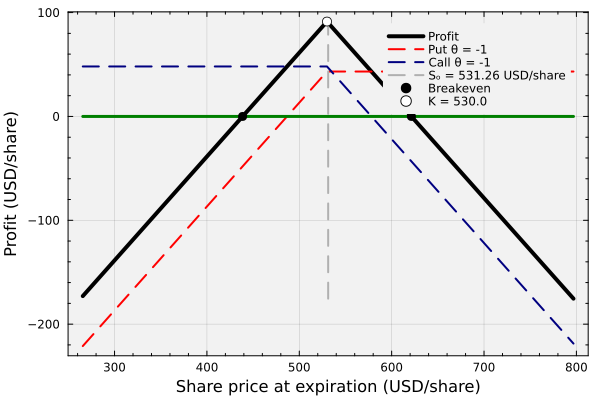

In [14]:
let
    
    # initialize -
    options_dataset =  optionschain;
    δ = 0.50; # range parameter for plotting
    premium_1 = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:Mid];
    premium_2 = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Call"), options_dataset)[1,:Mid];
    profit_at_K = -θ*𝒟*(premium_1 + premium_2); # profit at S(T) = K (USD/share)
    S = range((1-δ)*Sₒ,stop = (1+δ)*Sₒ, step=0.1) |> collect;
    number_of_steps = length(S);
    BEL = zeros(length(S))
    profit_array = profit([put_option_model, call_option_model], S; 𝒟 = 𝒟); # premiums grown to expiration
    
    breakeven_array = zeros(2,2);
    breakeven_array[1,1] = K + 𝒟*(premium_1 + premium_2); # S‡₊
    breakeven_array[2,1] = K - 𝒟*(premium_1 + premium_2); # S‡₋
    
    plot(profit_array[:,1], profit_array[:,4], lw=4, label="Profit", c=:black, 
        bg="gray95", 	background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(profit_array[:,1], profit_array[:,2], lw=2, label="Put θ = $(θ)", ls=:dash, c=:red)
    plot!(profit_array[:,1], profit_array[:,3], lw=2, label="Call θ = $(θ)", ls=:dash, c=:navyblue)
    plot!(S,BEL,lw=3, c=:green, label="")
    
    VLINE = zeros(number_of_steps, 2)
    VLINE[:,1] .= Sₒ*ones(number_of_steps)
    VLINE[:,2] .= range(minimum(profit_array[:,end]), stop = maximum(profit_array[:,end]), length = number_of_steps) |> collect;
    plot!(VLINE[:,1], VLINE[:,2], lw=2, c= :gray69, ls=:dash, label="Sₒ = $(Sₒ) USD/share")
    
    scatter!(breakeven_array[:,1], breakeven_array[:,2], c=:black, label="Breakeven", ms=5, xminorticks=true, yminorticks=true)
    scatter!([K],[profit_at_K], ms=5, label = "K = $(K)", msc=:black, mc=:white)
    
    xlabel!("Share price at expiration (USD/share)", fontsize=18)
    ylabel!("Profit (USD/share)", fontsize=18)
end

What are the breakeven points?

In [15]:
breakeven_array = let

    # initialize -
    options_dataset =  optionschain;
    premium_1 = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), options_dataset)[1,:Mid];
    premium_2 = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Call"), options_dataset)[1,:Mid];
    
    breakeven_array = zeros(2);
    breakeven_array[1] = K + 𝒟*(premium_1 + premium_2); # upper breakeven S‡₊ (USD/share)
    breakeven_array[2] = K - 𝒟*(premium_1 + premium_2); # lower breakeven S‡₋ (USD/share)

    breakeven_array;
end

2-element Vector{Float64}:
 621.3761674003179
 438.6238325996821

___

## Task 2: Compute the Probability of Profit (POP) and the Probability of Exercise (POE)
In this task, we compute the Probability of Profit (POP) of our short straddle and the Probability of Exercise (POE) of each leg at expiration.

To start, we simulate share prices at expiration under the risk-neutral probabilities $\mathbb{Q}$: geometric Brownian motion with drift $g_{y}$ and the at-the-money implied volatility. Later, we compare the probabilities with our belief $\mathbb{P}$, built from the SAGBM parameters we loaded earlier.

We'll save the GBM model in the `model::MyGeometricBrownianMotionEquityModel` variable:

In [16]:
model = let

    # initialize -
    ATM_IV = metadata["atm_IV"] |> x-> parse(Float64, x); # at-the-money implied volatility on the quote date (decimal)

    # risk-neutral ℚ: drift = risk-free rate, volatility = at-the-money implied volatility -
    model = build(MyGeometricBrownianMotionEquityModel, (
        μ = gᵧ,
        σ = ATM_IV
    ));

    model; # return
end

MyGeometricBrownianMotionEquityModel(0.04128677804517802, 0.5617)

Now that we have a populated [MyGeometricBrownianMotionEquityModel instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) holding the `AMD` data, let's generate `number_of_samples` possible future share price values using the [sample(...) function exported by the VLQuantitativeFinancePackage.jl package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}).
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) takes a `model::MyGeometricBrownianMotionEquityModel` instance as the first argument, along with the time values that we wish to sample: `T₁::Float64` is the start time, `T₂::Float64` is the stop time (in units of `years`), `Δt::Float64` is the time step (in units of `years`), and `Sₒ::Float64` denotes the initial share price (in units of `USD/share`). Finally, we pass in the number of samples we want to generate in the `number_of_paths` argument.
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) generates `number_of_paths` sample paths from $T_{1}\rightarrow{T}_{2}$ in steps of $\Delta{t}$. However, we only want the share prices corresponding to the duration of the contract, i.e., $T_{2} = \text{DTE}$. Thus, we pass the full `samples` array [using the Julia pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping) to a slicing operation where we select columns `2:end` of the last row (col 1 holds the time). We store the `number_of_paths` samples of the share price at $T_{2}$ in the `endpoint_samples::Array{Float64,1}` variable.

So what do we get?

In [17]:
endpoint_samples = let

    # initialize
    Random.seed!(5660); # reproducible samples
    number_of_samples = 50000; # how many samples do we want to generate?

    # compute the endpoint samples -
    endpoint = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0,
        T₂ = T,
        Δt = Δt,
        Sₒ = Sₒ
    ), number_of_paths = number_of_samples) |> samples -> samples[end,2:end]; # get last row from col 2 -> number_of_paths

    println("The mean projected price for GBM: $(mean(endpoint))");

    endpoint; # return
end;

The mean projected price for GBM: 534.7787839167826


#### Check: Are future GBM share prices log-normally distributed?
We expect geometric Brownian motion to generate __log-normally distributed__ share prices. We can check this expectation by performing an [exact one-sample Kolmogorov-Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#Kolmogorov-Smirnov-test) on the samples and the log-normal distribution that geometric Brownian motion predicts.
> __Hypothesis:__ The `H0:null hypothesis` for the test is the data (endpoint samples generated using geometric Brownian motion) comes from the LogNormal distribution `d_gbm`. The alternative hypothesis `H1:alternative` is the samples are not drawn from `d_gbm`.

Under geometric Brownian motion, $\ln S(T)$ is normal with mean $\ln S_{0}+(\mu-\sigma^{2}/2)T$ and standard deviation $\sigma\sqrt{T}$. Let's build this [LogNormal distribution exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.LogNormal) and save it in the `d_gbm::LogNormal` variable:

In [18]:
d_gbm = LogNormal(log(Sₒ) + (model.μ - model.σ^2/2)*T, model.σ*sqrt(T)); # distribution of S(T) under GBM

Next, execute [the exact one-sample Kolmogorov–Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#HypothesisTests.ExactOneSampleKSTest) and check the [pvalue](https://en.wikipedia.org/wiki/P-value). A large p-value means we fail to reject the `H0:null hypothesis`: the `endpoint_samples` are consistent with `d_gbm`.

In [19]:
test_result = ExactOneSampleKSTest(endpoint_samples, d_gbm)

Exact one sample Kolmogorov-Smirnov test
----------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.00342404

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.6009

Details:
    number of observations:   50000


`Unhide` the code block below to see how we plotted the future share price of `AMD` generated using a risk-neutral single asset geometric Brownian motion model parameterized using the implied volatility.
> __What do we see?__ The geometric Brownian motion generates future share prices that are [log-normally distributed](https://en.wikipedia.org/wiki/Log-normal_distribution) (blue line), and the log-normal distribution `d_gbm` (red line) describes them, consistent with the check above.

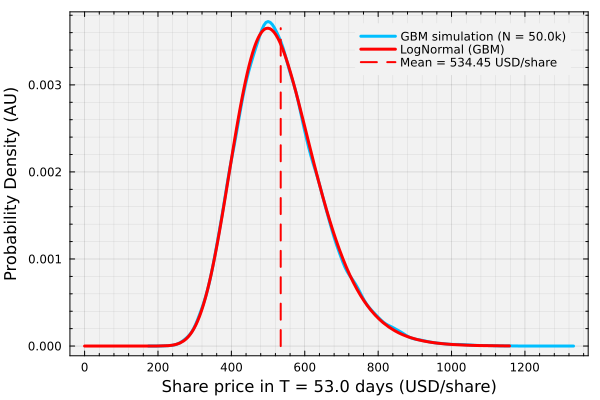

In [20]:
let

    # setup the mean line (for plotting) -
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)
    LX = ones(100) .* mean(d_gbm);
    LY = range(0, stop = maximum(pdf.(d_gbm, range(quantile(d_gbm,0.01), stop=quantile(d_gbm,0.99), length=100))), length = 100) |> collect;

    # plot -
    density(endpoint_samples, lw=3, c=:deepskyblue1, label="GBM simulation (N = $(length(endpoint_samples)/1000)k)")
    plot!(d_gbm, lw=3, label="LogNormal (GBM)", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, xminorticks=true, xminorgrid = true, yminorgrid = true)
    
    plot!(LX, LY, lw=2, ls=:dash, c=:red, label="Mean = $(round(mean(d_gbm),digits=2)) USD/share")
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Alternative: Future share price projection using implied volatility
Alternatively, we could use the __implied volatility__ to estimate the expected share price move over the time to expiration $T$ (years).
Suppose we construct a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal) $\mathcal{N}(\mu_{IV},\sigma_{IV})$ whose mean $\mu_{IV} = S_{0}\exp(g_{y}T)$ is the share price grown at the risk-free rate, or just $\mu_{IV}\approx{S}_{0}$ for short duration contracts, and whose standard deviation $\sigma_{IV}$ is:
$$
\sigma_{IV} = S_{0}\cdot\text{IV}\cdot\sqrt{T}
$$
where IV is the at-the-money implied volatility (decimal). We use the [Normal type exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal). This is only an approximate model of the future share price; it has a couple of issues: 
> __Watch out!__ This model assumes a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal), which is problematic because it can emit negative share prices. One way to fix this issue is to use a [Truncated Normal distribution](https://juliastats.org/Distributions.jl/stable/truncate/#Truncated-Distributions) instead.

However, despite the potential issues, this model is __widely__ used to generate quick estimates of future share price ranges using the forward-looking implied volatility. Let's save the Normal IV distribution $\mathcal{N}(\mu_{IV},\sigma_{IV})$ in the `d_IV::Normal` variable:

In [21]:
d_IV = let

    # initialize -
    ATM_IV = metadata["atm_IV"] |> x-> parse(Float64, x); # atm IV on purchase date, 10-26-2026
    
    # build the Normal model -
    d = Normal(Sₒ*exp(gᵧ*T), Sₒ*ATM_IV*sqrt(T)); # mean: Sₒ grown at gᵧ; standard deviation: Sₒ⋅IV⋅√T
    d; # return

end

Normal{Float64}(μ=534.4545050434095, σ=113.71114807827765)

`Unhide` the code block below to see how we plotted the `d_gbm::LogNormal` and `d_IV::Normal` future share price densities at `T = 53 days`.  

> __What do we see?__ The log-normal GBM share price distribution (blue line) is right-skewed and cannot admit negative share prices. However, the Normal IV distribution (red line) is symmetric around its mean, the share price grown at the risk-free rate, and can admit negative share prices, albeit with a small probability.

How do the two distributions compare?

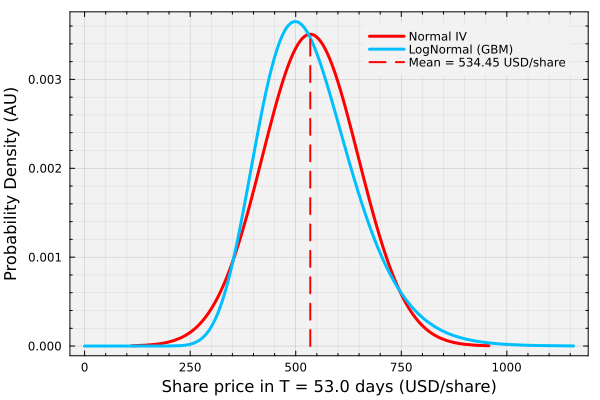

In [22]:
let

    # initialize -
    DTE = metadata["DTE"] |> x-> parse(Float64, x); # days to expiration (units: days)
    LX = ones(100) .* mean(d_IV);
    LY = range(0, stop = maximum(pdf.(d_IV, range(quantile(d_IV,0.01), stop=quantile(d_IV,0.99), length=100))), length = 100) |> collect;

    plot(d_IV, lw=3, label="Normal IV", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent, xminorticks=true, minorgrid = true);
    plot!(d_gbm, lw=3, label="LogNormal (GBM)", c=:deepskyblue1)
    plot!(LX, LY, lw=2, ls=:dash, c=:red, label="Mean = $(round(mean(d_IV),digits=2)) USD/share")
    
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Probability Density (AU)", fontsize=18)
end

### Probability of Profit (POP)
The POP for a long (short) straddle position is given by the probability that the future share price at expiration $S(T)$ is outside (inside) the breakeven points $S^{\ddagger}_{-}$ and $S^{\ddagger}_{+}$. Let's look at the two cases:

> __Probability of Profit (POP) for Long Straddle__ 
> 
> The POP for a long straddle position is the probability that the future share price at expiration $S(T)$ is either greater than the upper breakeven point $S^{\ddagger}_{+}$ or less than the lower breakeven point $S^{\ddagger}_{-}$:
> $$
\begin{align*}
\text{POP} &= \mathbb{P}(S(T) > S^{\ddagger}_{+}) + \mathbb{P}(S(T) < S^{\ddagger}_{-}) \\
& = 1 - \mathbb{P}(S^{\ddagger}_{-} \leq S(T) \leq S^{\ddagger}_{+}) \\
& = 1 - \left[F_{S}(S^{\ddagger}_{+}) - F_{S}(S^{\ddagger}_{-})\right]
\end{align*}
$$
> where $F_{S}(x)$ is the cumulative distribution function (CDF) of the future share price at expiration, i.e., $F_{S}(x) = \mathbb{P}(S(T) \leq x)$.

However, if we were trading a short straddle position, the POP would be given by:
> __Probability of Profit (POP) for Short Straddle__ 
> 
> The POP for a short straddle position is the probability that the future share price at expiration $S(T)$ is between the lower breakeven point $S^{\ddagger}_{-}$ and the upper breakeven point $S^{\ddagger}_{+}$:
> $$
\begin{align*}
\text{POP} &= \mathbb{P}(S^{\ddagger}_{-} < S(T) < S^{\ddagger}_{+}) \\
& = F_{S}(S^{\ddagger}_{+}) - F_{S}(S^{\ddagger}_{-})
\end{align*}
$$
> where $F_{S}(x)$ is the cumulative distribution function (CDF) of the future share price at expiration, i.e., $F_{S}(x) = \mathbb{P}(S(T) \leq x)$.

### Probability of Exercise (POE) and Our Belief
Each leg has its own probability of exercise. The put is exercised if $S(T)<K-0.01$ and the call if $S(T)>K+0.01$, so $\text{POE}_{p}=F_{S}(K-0.01)$ and $\text{POE}_{c}=1-F_{S}(K+0.01)$.

So far, we used the risk-neutral probabilities $\mathbb{Q}$, the probabilities inside the market price. Our belief $\mathbb{P}$ uses the SAGBM parameters instead: geometric Brownian motion with drift $\hat{\mu}=\hat{\mu}_{g}+\hat{\sigma}^{2}/2$ and volatility $\hat{\sigma}$, where $\hat{\mu}_{g}$ (the `drift` column) and $\hat{\sigma}$ (the `volatility` column) are the AMD estimates we loaded earlier. Let's compute the POP of our position and each leg's POE for five distributions of the share price at expiration:
* __Our belief $\mathbb{P}$:__ log-normal, with drift $\hat{\mu}$ and volatility $\hat{\sigma}$.
* __Risk-neutral $\mathbb{Q}$:__ log-normal, with drift $g_{y}$ and the at-the-money implied volatility, the distribution `d_gbm` above.
* __Two mixed cases:__ the historical drift $\hat{\mu}$ with the implied volatility, and the risk-free rate $g_{y}$ with the historical volatility $\hat{\sigma}$. Each changes one input of $\mathbb{Q}$, so we can see which input moves the probabilities.
* __Normal IV:__ the quick approximation `d_IV` above, close to $\mathbb{Q}$ but not log-normal.

So what do we get?

In [23]:
let

    # initialize: the five share price distributions at expiration -
    S₊ = breakeven_array[1]; # upper breakeven S‡₊ (USD/share)
    S₋ = breakeven_array[2]; # lower breakeven S‡₋ (USD/share)
    amd = only(eachrow(filter(:ticker => ==("AMD"), parameters_df))); # AMD's SAGBM estimates
    μ̂_g = amd.drift; # mean growth rate (1/yr)
    σ̂ = amd.volatility; # historical volatility (1/sqrt(yr))
    μ̂ = μ̂_g + σ̂^2/2; # GBM drift of our belief ℙ (1/yr)
    cases = [
        ("our belief ℙ", LogNormal(log(Sₒ) + (μ̂ - σ̂^2/2)*T, σ̂*sqrt(T))),
        ("historical drift, implied volatility", LogNormal(log(Sₒ) + (μ̂ - model.σ^2/2)*T, model.σ*sqrt(T))),
        ("risk-neutral ℚ", d_gbm),
        ("risk-free drift, historical volatility", LogNormal(log(Sₒ) + (gᵧ - σ̂^2/2)*T, σ̂*sqrt(T))),
        ("Normal IV (approximates ℚ)", d_IV)
    ];

    # the POP of our position, and each leg's POE -
    df = DataFrame(case = String[], POP = Float64[], POE_put = Float64[], POE_call = Float64[]);
    for (label, d) ∈ cases
        inside = cdf(d, S₊) - cdf(d, S₋); # probability that S(T) finishes between the breakevens
        POP = (θ == -1) ? inside : 1 - inside; # a short straddle profits inside, a long straddle outside
        push!(df, (label, POP, cdf(d, K - 0.01), 1 - cdf(d, K + 0.01))); # POEs at K ∓ 0.01
    end
    pretty_table(df; column_labels = ["distribution of S(T)", "POP ($(θ == -1 ? "short" : "long") straddle)", "POE put", "POE call"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.4f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact),
        fit_table_in_display_horizontally = false);
    println("our belief ℙ: μ̂_g = $(round(μ̂_g, digits = 4)), σ̂ = $(round(σ̂, digits = 4)), μ̂ = $(round(μ̂, digits = 4)) (1/yr)");
    println("risk-neutral ℚ: gᵧ = $(round(gᵧ, digits = 4)) (1/yr), ATM IV = $(model.σ)");

    # checks: the ℚ row is d_gbm, and every probability is between 0 and 1 -
    @assert isapprox(df.POE_put[3], cdf(d_gbm, K - 0.01); atol = 1e-12) "the ℚ row does not match d_gbm"
    @assert all(0 .≤ Matrix(df[:, 2:4]) .≤ 1) "a probability is outside [0, 1]"
end

 ---------------------------------------- ---------------------- --------- ----------
  distribution of S(T)                     POP (short straddle)   POE put   POE call 
 ---------------------------------------- ---------------------- --------- ----------
  our belief ℙ                                           0.6175    0.3570     0.6429
  historical drift, implied volatility                   0.5564    0.3902     0.6097
  risk-neutral ℚ                                         0.5841    0.5270     0.4729
  risk-free drift, historical volatility                 0.6644    0.5175     0.4824
  Normal IV (approximates ℚ)                             0.5780    0.4843     0.5156
 ---------------------------------------- ---------------------- --------- ----------
our belief ℙ: μ̂_g = 0.4397, σ̂ = 0.4743, μ̂ = 0.5521 (1/yr)
risk-neutral ℚ: gᵧ = 0.0413 (1/yr), ATM IV = 0.5617


> __What do we see?__
>
> * __The POP:__ Our belief $\mathbb{P}$ gives the short straddle a higher POP than $\mathbb{Q}$. The two mixed rows show why: the lower historical volatility alone raises the POP, and the larger historical drift alone lowers it. Here the volatility wins.
> * __The POE:__ Under $\mathbb{Q}$, the put and the call are about equally likely to finish in the money. The rows with the drift $\hat{\mu}$ make the call far more likely to be exercised than the put.
> * __The Normal IV approximation:__ It gives nearly the same POP as $\mathbb{Q}$, but it tilts the POE toward the call. A Normal distribution is symmetric about its mean, while the log-normal distribution puts its median below its mean.

___

## Task 3: Did we make money on the straddle?
In this task, we close our short straddle after AMD's earnings release and compute the profit or loss.

> __Earnings Release:__ [AMD reports its third-quarter 2026 results](https://ir.amd.com/news-events/press-releases/detail/1300/amd-to-report-fiscal-third-quarter-2026-financial-results) on `2026-11-03` after market close, after we priced the contracts on `2026-10-26`. Earnings releases can move the share price sharply in either direction. A short straddle profits if the share price stays between the breakevens, and a long straddle if it moves outside them.

The release comes weeks before expiration, so the breakevens alone cannot tell us whether we made money. Both legs still carry extrinsic value, and closing a short straddle means buying both legs back at their premiums on that day, $\mathcal{P}^{\prime}_{p}$ and $\mathcal{P}^{\prime}_{c}$. If we close $\tau$ years after we opened, the profit per share is:
$$
\hat{P}_{\mathcal{C}}(\tau) = \theta\cdot\Bigl[(\mathcal{P}^{\prime}_{p}+\mathcal{P}^{\prime}_{c})-\mathcal{D}_{\tau,0}(g_{y})\cdot(\mathcal{P}_{p}+\mathcal{P}_{c})\Bigr]
$$
where $\mathcal{D}_{\tau,0}(g_{y})=e^{g_{y}\tau}$. For our short straddle ($\theta=-1$), this is the credit grown to the closing day minus the cost to buy both legs back.

Until the release, `post_release_ticker` is `missing` and the cells below print a pending message. After the release, download the AMD chain for the same expiration, save it as a new dataset, set `post_release_ticker` to its name, and rerun this task.

In [24]:
post_release_ticker = missing; # name of the AMD chain saved after the 2026-11-03 release (TODO: set it, for example "amd-2026-post")

What is our profit or loss if we close the straddle after the release?

In [25]:
ismissing(post_release_ticker) ? println("Pending: set post_release_ticker after the 2026-11-03 earnings release and rerun this task.") : let

    # initialize: the chain after the release -
    post = MyOptionsChainDataSet(ticker = post_release_ticker);
    chain = post.data;
    put_rows = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Put"), chain); # the K put after the release
    call_rows = filter([:Strike,:Type] => (x,y) -> (x == K && y == "Call"), chain); # the K call after the release

    # checks: a chain from the close after the release, same expiration, one put and one call at K -
    @assert Date(post.metadata["purchase_date"]) ≥ Date(2026, 11, 4) "the post-release chain must be from 2026-11-04 or later (the release is after the close on 2026-11-03)"
    @assert post.metadata["expiration_date"] == metadata["expiration_date"] "the post-release chain must have the same expiration"
    @assert nrow(put_rows) == 1 && nrow(call_rows) == 1 "expected exactly one put and one call at K = $(K)"

    S_post = post.metadata["underlying_share_price_mid"] |> x-> parse(Float64, x); # share price after the release (USD/share)
    days_held = (Date(post.metadata["purchase_date"]) - Date(metadata["purchase_date"])).value; # days from opening to closing
    τ = days_held*Δt; # time from opening to closing (years)
    𝒟_τ = exp(gᵧ*τ); # accumulation factor from opening to closing (dimensionless)

    # premiums: when we opened, and when we close -
    opened = put_option_model.premium + call_option_model.premium; # 𝒫_p + 𝒫_c (USD/share)
    P′_p = put_rows[1,:Mid]; # put premium after the release (USD/share)
    P′_c = call_rows[1,:Mid]; # call premium after the release (USD/share)
    profit_per_share = θ*((P′_p + P′_c) - 𝒟_τ*opened); # (USD/share)

    # show the results -
    df = DataFrame(
        quantity = ["share price after the release", "days held", "premiums when opened, 𝒫_p + 𝒫_c",
            "premiums when closed, 𝒫′_p + 𝒫′_c", "profit or loss per share", "profit or loss, one straddle (100 shares)"],
        value = [S_post, days_held, opened, P′_p + P′_c, profit_per_share, 100*profit_per_share],
        units = ["USD/share", "days", "USD/share", "USD/share", "USD/share", "USD"]);
    pretty_table(df; column_labels = ["quantity", "value", "units"], alignment = [:l, :r, :l],
        formatters = [fmt__printf("%.2f", [2])], fit_table_in_display_horizontally = false,
        table_format = TextTableFormat(borders = text_table_borders__compact));
    println("Breakevens at expiration: S‡₋ = $(round(breakeven_array[2], digits = 2)) and S‡₊ = $(round(breakeven_array[1], digits = 2)) USD/share");
end

Pending: set post_release_ticker after the 2026-11-03 earnings release and rerun this task.


__Why not compare the share price with the breakevens?__ The breakevens describe the profit at expiration. After the release, each leg's premium is its intrinsic value plus the extrinsic value still left in it, so a share price between the breakevens does not by itself mean the short straddle made money. The implied volatility of the legs usually falls after an earnings release, which lowers their extrinsic value; a straddle seller is betting on that drop.

___

## Summary
In this example, we sold a straddle on AMD before its earnings release, computed its profit at expiration and its breakevens, and computed its probability of profit and each leg's probability of exercise under our belief and under the risk-neutral probabilities.

> __Key Takeaways:__
>
> * __Straddles have two breakeven points:__ We computed the profit at expiration of the short straddle as the credit grown to expiration minus the payoffs of both legs. It breaks even at the strike price plus or minus the premiums grown to expiration, and the short straddle profits only when the share price finishes between these two points.
> * __The probability of profit depends on whose probabilities we use:__ We computed the POP of the short straddle and each leg's POE from log-normal share prices under our belief $\mathbb{P}$ and under the risk-neutral probabilities $\mathbb{Q}$. Changing one input at a time showed that the lower historical volatility raised the POP under $\mathbb{P}$, while the larger historical drift made the call more likely to be exercised than the put.
> * __Closing early costs the extrinsic value left in the legs:__ We wrote the profit from closing after the earnings release as the credit grown to that day minus the cost to buy both legs back. Before expiration, those premiums still include extrinsic value, so the profit depends on the premiums when we close, not only on where the share price is relative to the breakevens.

Selling a straddle collects a large credit but loses money if the share price moves far in either direction, so it suits a trader who expects the share price to stay near the strike price.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.